# 02 · Features & leakage

A **feature** is a number we know *before* a match that might help predict what happens in it: minutes in recent
games, expected goals per 90, the opponent's strength…

The golden rule: **a feature for gameweek *g* may only use information available at *g*'s deadline.**
Breaking it is called **leakage**. It makes a model look brilliant in testing and useless in real life.

Code: [`fpl_engine/features/build.py`](../fpl_engine/features/build.py) · tests: [`tests/test_features_leakage.py`](../tests/test_features_leakage.py)

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from fpl_engine import db
from fpl_engine.features import load_base, build_features, FeatureConfig, rotation_relevant
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 200, 'display.max_columns', 30)
with db.connect() as conn:
    base = load_base(conn)          # 2021-22 onwards; 2021-22 is a warm-up season (history only, never a target)
f = build_features(base)
print(f'{len(f):,} player-fixture rows, {f.shape[1]} columns')
# evaluation population: rotation-relevant players, target seasons 2022-23 onwards
ev = f[rotation_relevant(f) & (f.season >= '2022-23')].copy()
ev['y_gi'] = ev.y_goals + ev.y_assists
print(f'{len(ev):,} rotation-relevant rows in 2022-23 →')

145,943 player-fixture rows, 77 columns
49,574 rotation-relevant rows in 2022-23 →


**Targets** (`y_*` columns) are what actually happened. `y_points` is the score **re-scored under 2026-27 rules**
with definition-adjusted defensive counts (your decisions after notebooks 01 and 01b).

## 1 · The leakage trap, live

Say we want "average points over the last 5 matches" as a feature. The obvious code is a rolling mean, but a plain
rolling mean **includes the match we're trying to predict**.

In [2]:
b = base.sort_values(['player_id', 'kickoff_time']).copy()
g = b.groupby('player_id').points
b['leaky_last5']   = g.transform(lambda x: x.rolling(5, min_periods=1).mean())           # includes this match ❌
b['correct_last5'] = g.transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())  # strictly before ✅
b = b.merge(ev[['player_id', 'fixture_id']], on=['player_id', 'fixture_id'])
for col in ['leaky_last5', 'correct_last5']:
    mae = (b[col] - b.points).abs().mean()
    print(f"{col:14s}  correlation with actual points {b[col].corr(b.points):.3f}   MAE {mae:.3f}")

leaky_last5     correlation with actual points 0.571   MAE 1.799
correct_last5   correlation with actual points 0.255   MAE 2.233


The leaky version looks far better. It's peeking at the answer: one fifth of its "average" *is* the score
we're predicting. In real use that number doesn't exist yet. Models trained on leaky features learn to lean on them and
then fall apart live.

### The subtler trap: double gameweeks
Even `shift(1)` leaks in a **double gameweek**: when predicting a player's *second* match, the first one has already been
played, but at the *deadline* (when you pick your team) neither has. So our builder takes each player's state **at the end
of the previous gameweek** and gives both matches the same history.

In [3]:
dgw = f[f.dgw == 1].sort_values(['player_id', 'kickoff_time'])
pairs = dgw.groupby(['player_id', 'gw_key']).filter(lambda x: len(x) == 2)
same = pairs.groupby(['player_id', 'gw_key'])[['mins_l5', 'xgi90_l5', 'points90_l5']].nunique(dropna=False).le(1).all(axis=1)
print(f"{len(pairs) // 2:,} double-gameweek player pairs; identical pre-deadline features for both matches: {same.mean():.0%}")

5,521 double-gameweek player pairs; identical pre-deadline features for both matches: 100%


Both protections are enforced by an **automated test**: it rebuilds features after replacing every result from
gameweek *g* onwards with random junk, and checks gameweek *g*'s features don't change at all. It runs with every
`pytest`, so a future code change can't quietly reintroduce leakage.

## 2 · What the feature table looks like

One player's recent history, as the model sees it before each deadline:

In [4]:
recent = f[f.season == '2025-26']
star = recent.groupby('player_id').y_points.sum().idxmax()
with db.connect() as conn:
    name = conn.execute('SELECT web_name FROM core.players WHERE player_id = %s', (int(star),)).fetchone()[0]
print(name)
cols = ['gameweek', 'was_home', 'mins_l5', 'starts_l5', 'xg90_l5', 'xa90_l5', 'xgi90_ewm5', 'dc90_l5', 'points90_l5',
        'days_since_last', 'y_minutes', 'y_points']
f[(f.player_id == star) & (f.season == '2025-26')][cols].head(12).round(2)

Haaland


,gameweek,was_home,mins_l5,starts_l5,xg90_l5,xa90_l5,xgi90_ewm5,dc90_l5,points90_l5,days_since_last,y_minutes,y_points
74149,1,0.0,51.2,0.6,0.32,0.07,0.45,3.00,4.16,60.00,72.0,13.0
74150,2,1.0,65.6,0.8,0.50,0.06,0.59,2.92,5.16,6.79,90.0,2.0
74151,3,0.0,83.6,1.0,0.49,0.09,0.59,3.11,4.86,8.06,90.0,9.0
74152,4,1.0,83.6,1.0,0.62,0.07,0.64,2.77,5.52,14.10,86.0,13.0
74153,5,0.0,84.4,1.0,0.78,0.06,0.72,3.65,6.53,7.00,75.0,9.0
74154,6,1.0,82.6,1.0,0.74,0.06,0.69,4.44,6.87,5.94,90.0,16.0
74155,7,0.0,86.2,1.0,0.65,0.08,0.72,4.63,7.02,8.06,90.0,8.0
74156,8,1.0,86.2,1.0,0.64,0.06,0.66,4.28,7.58,12.94,90.0,13.0
74157,9,0.0,86.2,1.0,0.60,0.06,0.67,4.80,7.95,8.00,90.0,2.0
74158,10,1.0,87.0,1.0,0.45,0.06,0.61,3.91,6.90,7.10,81.0,13.0


Feature families:

| Family | Columns | Meaning |
|---|---|---|
| Playing time | `mins_l{3,5,10}`, `starts_l*`, `apps_l*`, `days_since_last` | average minutes / share of 60+ / share played over the last N **squad fixtures** (bench games count as 0) |
| Underlying per-90 | `xg90_*`, `xa90_*`, `xgi90_*`, `dc90_*`, `bps90_*`, `bonus90_*` | rates per 90 minutes played, over the last 5 or 10 fixtures, or exponentially weighted (`ewm5`) |
| Form | `points90_*` | points per 90 (re-scored) |
| Context | `was_home`, `price`, `pos_*`, `dgw` | known before the deadline |

Team strength and opponent features come in notebook 05.

## 3 · Which window? (your call)

Fewer matches = more up to date but noisier. More matches = stable but slow to react. We test each window's
**correlation with what happened next**, for rotation-relevant players. Higher = more useful.

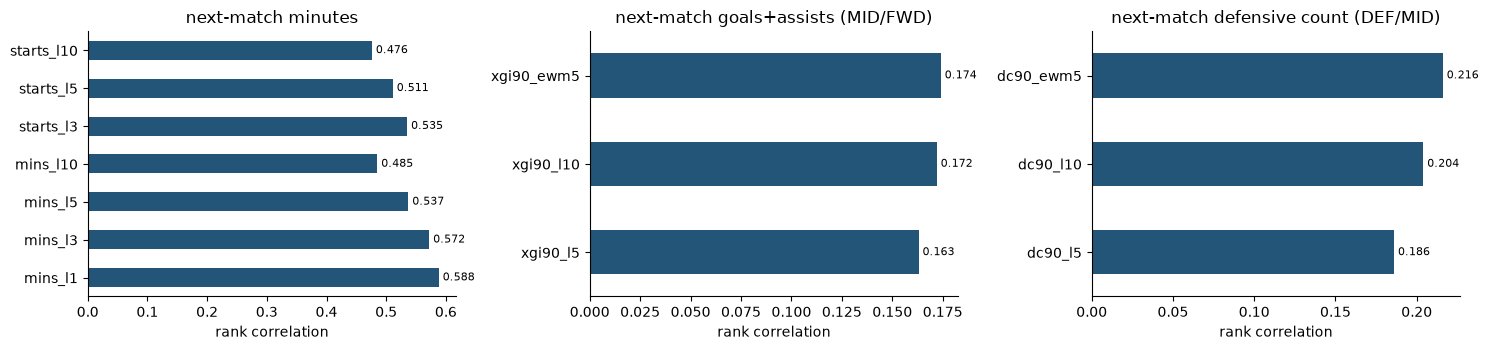

In [5]:
def corr_table(cands, target, data=ev, method='spearman'):
    return pd.Series({c: data[c].corr(data[target], method=method) for c in cands}).round(3)

minutes = corr_table(['mins_l1', 'mins_l3', 'mins_l5', 'mins_l10', 'starts_l3', 'starts_l5', 'starts_l10'], 'y_minutes')
attack = corr_table(['xgi90_l5', 'xgi90_l10', 'xgi90_ewm5'], 'y_gi', data=ev[ev.position.isin(['MID', 'FWD'])])
defence = corr_table(['dc90_l5', 'dc90_l10', 'dc90_ewm5'], 'y_dc', data=ev[ev.position.isin(['DEF', 'MID'])])
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (t, s) in zip(axes, [('next-match minutes', minutes), ('next-match goals+assists (MID/FWD)', attack),
                             ('next-match defensive count (DEF/MID)', defence)]):
    s.plot.barh(ax=ax, color='#257'); ax.set_title(t); ax.set_xlabel('rank correlation')
    for i, v in enumerate(s): ax.text(v, i, f' {v:.3f}', va='center', fontsize=8)
plt.tight_layout(); plt.show()

Typical pattern: for **minutes**, the most recent matches matter most (managers change line-ups); for **underlying
rates** like xGI and defensive actions, longer or exponentially-weighted windows win because single matches are noisy.

## 4 · Underlying numbers vs form (your earlier question)

Does **xGI per 90** (underlying) or **points per 90** (form) better predict a midfielder/forward's next-match points?

In [6]:
mf = ev[ev.position.isin(['MID', 'FWD'])]
uf = pd.DataFrame({
    'underlying: xGI per 90 (last 10)': [mf['xgi90_l10'].corr(mf.y_points, method='spearman'), mf['xgi90_l10'].corr(mf.y_gi, method='spearman')],
    'form: points per 90 (last 10)':     [mf['points90_l10'].corr(mf.y_points, method='spearman'), mf['points90_l10'].corr(mf.y_gi, method='spearman')],
}, index=['→ next points', '→ next goals+assists']).T.round(3)
uf

,→ next points,→ next goals+assists
underlying: xGI per 90 (last 10),0.088,0.172
form: points per 90 (last 10),0.039,0.106


Underlying numbers predict attacking returns better than points form, which supports your instinct.
(The component model will use xG/xA directly for goals and assists; form features stay available to the direct benchmark.)

## 5 · Shrinkage: don't trust tiny samples

A defender who played 30 minutes and had one shot of 0.4 xG has an "xG per 90" of 1.2, higher than Haaland. That's
noise. **Shrinkage** blends a player's rate with his position's average, weighted by how much he's played:

`rate = (player's total + k × position average) / (player's 90s + k)`, where `k` = how many matches' worth of
"benefit of the doubt" the average gets. Below: which `k` predicts best?

In [7]:
rows = []
for k_min in [0, 90, 270, 540, 900]:
    ff = build_features(base, FeatureConfig(shrink_minutes=max(k_min, 1e-6), rate_windows=(10,), ewm_halflives=()))
    e = ff[rotation_relevant(ff) & (ff.season >= '2022-23')]
    e = e.assign(y_gi=e.y_goals + e.y_assists)
    mf_ = e[e.position.isin(['MID', 'FWD'])]
    low = mf_[mf_.mins_l10 * mf_.n_l10 < 450]                      # fewer than 5 full matches in the window
    rows.append({'k (minutes)': k_min,
                 'xGI→goals+assists, all MID/FWD': mf_.xgi90_l10.corr(mf_.y_gi, method='spearman'),
                 '…players with < 450 min': low.xgi90_l10.corr(low.y_gi, method='spearman'),
                 'defensive rate→count, DEF': e[e.position == 'DEF'].dc90_l10.corr(e[e.position == 'DEF'].y_dc, method='spearman')})
shrink = pd.DataFrame(rows).set_index('k (minutes)').round(4); shrink

,"xGI→goals+assists, all MID/FWD",…players with < 450 min,"defensive rate→count, DEF"
k (minutes),,,
0,0.1461,0.0925,0.2049
90,0.1577,0.1036,0.2032
270,0.1672,0.1128,0.2017
540,0.1720,0.1179,0.2000
900,0.1732,0.1178,0.1985


---
## ✅ Decisions (made with you, 2026-11-23)

1. **Windows:** keep last-3/5/10 and EWM as candidates; the models choose (checked in notebook 08).
2. **Shrinkage:** `k` = **540 minutes** for attacking/scoring stats (xG, xA, xGI, points, bonus, BPS) and **90 minutes**
   for defensive counts. Defensive actions happen many times a match, so small samples are already informative.
3. **Long absences:** `days_since_last` capped at **60**, plus a `long_absence` flag (gap > 60 days: long injury,
   new signing, summer break).
4. **Double gameweeks:** a gameweek prediction is the **sum of the per-fixture predictions**. Features are always
   **per match** (last-N *fixtures*, per-90 rates), so a DGW haul enters history as two matches, never as one doubled
   gameweek total. A test enforces this.